# Predicting Lung Function in Children and Young Adults Using Linear Regression

## Objective

Predict forced expiratory volume (FEV) using age, height, sex, and smoking status.

**Research question:** How accurately can basic physical measurements predict lung function in children and young adult?

## Dataset

The dataset is publicly available through the Journal of Statistics Education. It contains 654 observations of children and young adults aged 3–19 from East Boston, collected during the 1970s.

- [Download the data](https://jse.amstat.org/datasets/fev.dat.txt)
- [Dataset documentation](https://jse.amstat.org/datasets/fev.txt)
- [Published analysis](https://jse.amstat.org/v13n2/datasets.kahn.html)

This project uses existing public research data (no new patient data are collected).

## Variables

- **fev:** Volume exhaled of a forced breath, in litres (Target variable)
- **age:** Age in years (Predictor)
- **height:** Height in inches (Predictor)
- **sex:** 0= female, 1 = male (Predictor)
- **smoke:** 0 = non-smoker, 1 = smoker (Predictor)

## Methodology

1. Inspect the dataset and check missing values and unusual measurements.
2. Explore relationships using scatterplots and Pearson correlations.
3. Divide the data into training and test sets.
5. Fit multiple linear regression using all four predictors.
6. Compare multiple linear regression model with a baseline model.
7. Use cross-validation within the training set to assess consistency.
8. Evaluate the selected model.

## Evaluation Metrics

- **MAE:** average absolute prediction error in litres.
- **RMSE:** prediction error in litres, emphasizing larger mistakes.
- **R²:** performance relative to predicting the evaluation-set mean.
- Compare predicted FEV with actual test values.
- Residual Plot to check prediction errors.
- Q-Q plot to check for normality.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
url = "https://jse.amstat.org/datasets/fev.dat.txt"

df_fev = pd.read_csv(url, sep=r"\s+", header=None, names=["age", "fev", "height", "sex", "smoke"])

print(df_fev.shape)  # Expected: (654, 5)
df_fev.head(10)

(654, 5)


,age,fev,height,sex,smoke
0,9,1.708,57.0,0,0
1,8,1.724,67.5,0,0
2,7,1.720,54.5,0,0
3,9,1.558,53.0,1,0
4,9,1.895,57.0,1,0
5,8,2.336,61.0,0,0
6,6,1.919,58.0,0,0
7,6,1.415,56.0,0,0
8,8,1.987,58.5,0,0
9,9,1.942,60.0,0,0


In [3]:
print("Shape:", df_fev.shape)

Shape: (654, 5)


In [4]:
df_fev.info()

<class 'pandas.DataFrame'>
RangeIndex: 654 entries, 0 to 653
Data columns (total 5 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   age     654 non-null    int64  
 1   fev     654 non-null    float64
 2   height  654 non-null    float64
 3   sex     654 non-null    int64  
 4   smoke   654 non-null    int64  
dtypes: float64(2), int64(3)
memory usage: 25.7 KB


In [5]:
df_fev.describe()

,age,fev,height,sex,smoke
count,654.000000,654.000000,654.000000,654.000000,654.000000
mean,9.931193,2.636780,61.143578,0.513761,0.099388
std,2.953935,0.867059,5.703513,0.500193,0.299412
min,3.000000,0.791000,46.000000,0.000000,0.000000
25%,8.000000,1.981000,57.000000,0.000000,0.000000
50%,10.000000,2.547500,61.500000,1.000000,0.000000
75%,12.000000,3.118500,65.500000,1.000000,0.000000
max,19.000000,5.793000,74.000000,1.000000,1.000000


In [6]:
print("Sex (0 = female, 1 = male):")
print(df_fev["sex"].value_counts())

print("Smoking (0 = no, 1 = yes):")
print(df_fev["smoke"].value_counts())

Sex (0 = female, 1 = male):
sex
1    336
0    318
Name: count, dtype: int64
Smoking (0 = no, 1 = yes):
smoke
0    589
1     65
Name: count, dtype: int64


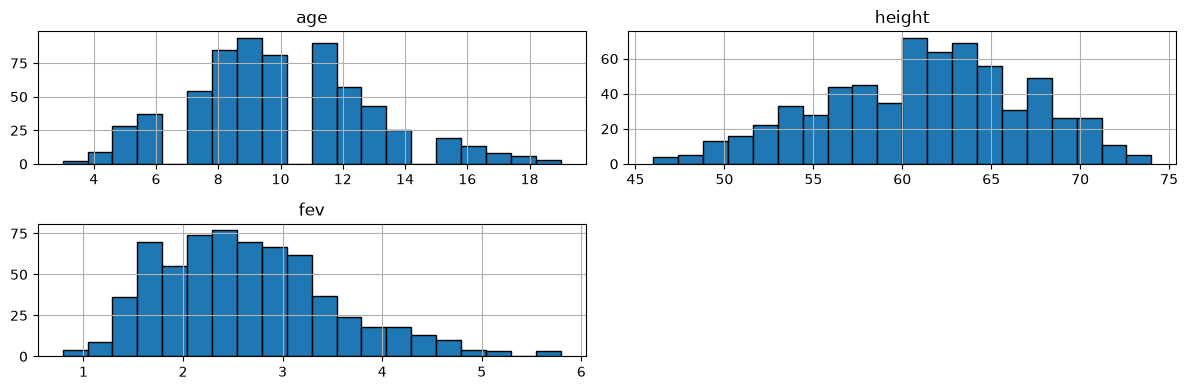

In [7]:
df_fev[["age", "height", "fev"]].hist(bins=20, figsize=(12, 4), edgecolor="black")

plt.tight_layout()
plt.show()

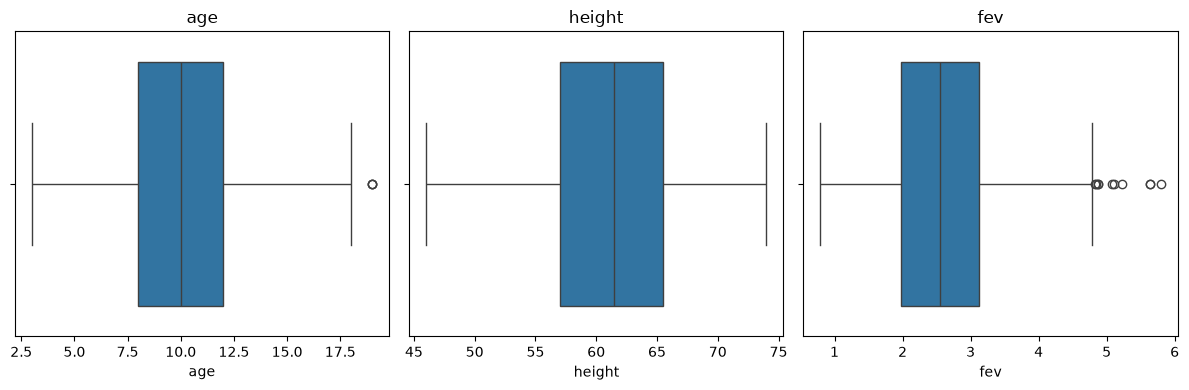

In [8]:
fig, axes = plt.subplots(1, 3, figsize=(12, 4))

for ax, column in zip(axes, ["age", "height", "fev"]):
    sns.boxplot(x=df_fev[column], ax=ax)
    ax.set_title(column)

plt.tight_layout()
plt.show()

Points beyond the whiskers are potential outliers, not confirmed errors.

In [9]:
from sklearn.model_selection import train_test_split

# Select features and target
X = df_fev[["age", "height", "sex", "smoke"]]
y = df_fev["fev"]

# Split data: 80% training, 20% testing
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
train_data = X_train.copy()
train_data["fev"] = y_train

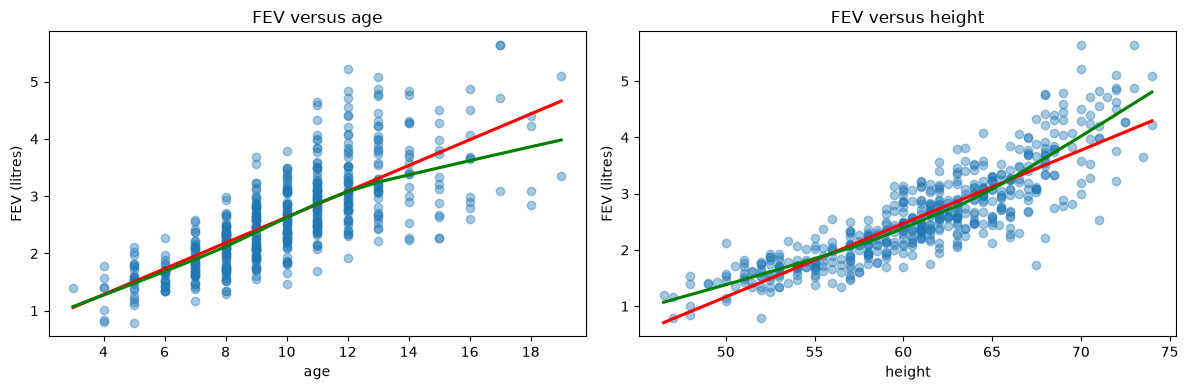

In [10]:
# Compare a straight line (red) with a smooth trend (green)
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

for ax, column in zip(axes, ["age", "height"]):
    sns.regplot(
        data=train_data, x=column, y="fev", ax=ax,
        ci=None,
        scatter_kws={"alpha": 0.4},
        line_kws={"color": "red"})
    sns.regplot(
        data=train_data, x=column, y="fev", ax=ax,
        lowess=True, scatter=False,
        line_kws={"color": "green"})
    ax.set_title(f"FEV versus {column}")
    ax.set_ylabel("FEV (litres)")

plt.tight_layout()
plt.show()

The scatter plots show positive relationships between FEV and both age and height. However, the LOWESS curves indicate some deviations from the straight regression lines, suggesting possible nonlinear relationships.

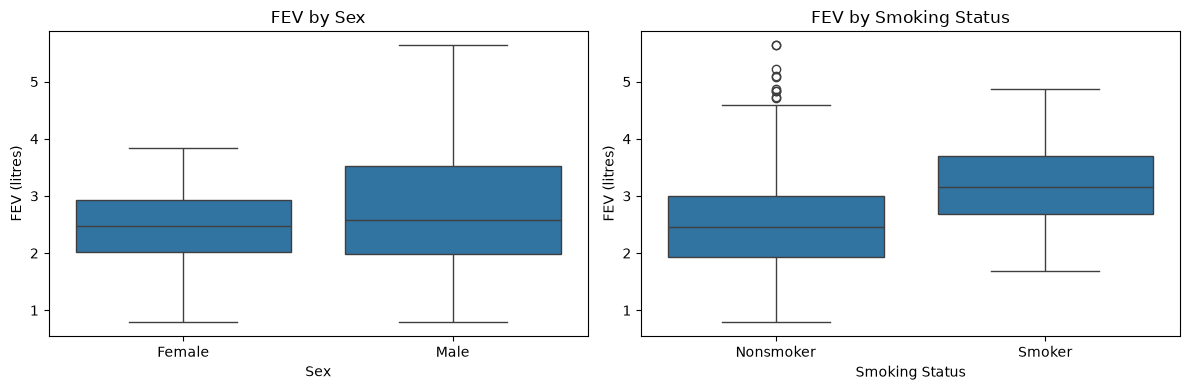

In [11]:
# Compare FEV distributions by sex and smoking status
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

sns.boxplot(data=train_data, x="sex", y="fev", order=[0, 1], ax=axes[0])

axes[0].set_xticks([0, 1])
axes[0].set_xticklabels(["Female", "Male"])
axes[0].set_xlabel("Sex")
axes[0].set_ylabel("FEV (litres)")
axes[0].set_title("FEV by Sex")

sns.boxplot(data=train_data, x="smoke", y="fev", order=[0, 1], ax=axes[1])
axes[1].set_xticks([0, 1])
axes[1].set_xticklabels(["Nonsmoker", "Smoker"])
axes[1].set_xlabel("Smoking Status")
axes[1].set_ylabel("FEV (litres)")
axes[1].set_title("FEV by Smoking Status")

plt.tight_layout()
plt.show()

The boxplots show that males have a slightly higher median FEV than females, with greater variability. Smokers also have a higher median FEV than nonsmokers. However, this difference may be influenced by other factors, such as age and height.

age       0.750599
height    0.863989
sex       0.194891
smoke     0.238040
dtype: float64


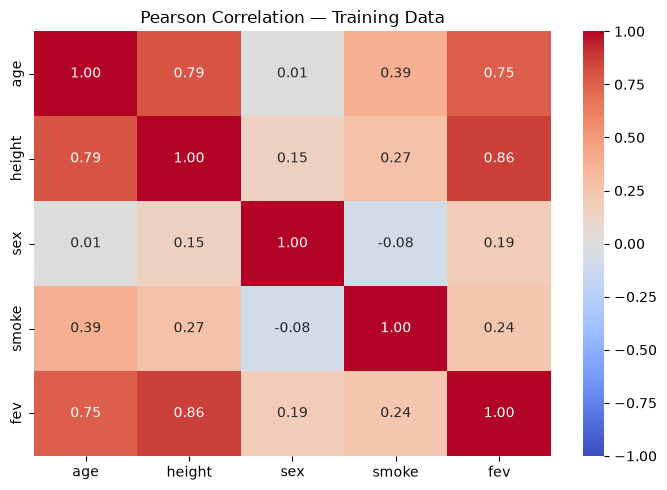

In [12]:
# Correlation between each predictor and FEV
pearson_corr = X_train.corrwith(y_train, method="pearson")
print(pearson_corr)

# Correlation heatmap
plt.figure(figsize=(7, 5))
sns.heatmap(train_data.corr(method="pearson"), annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1, center=0)

plt.title("Pearson Correlation — Training Data")
plt.tight_layout()
plt.show()

- **Height**	0.864: 	Strong positive relationship: taller children tend to have higher FEV.
- **Age**	0.751: 	Strong positive relationship: older children tend to have higher FEV.
- **Sex**	0.195: 	Weak positive association between sex and FEV.
- **Smoking**	0.238:	Weak positive association between smoking and FEV.

In [13]:
from sklearn.linear_model import LinearRegression
from sklearn.dummy import DummyRegressor
from sklearn.metrics import (mean_absolute_error, mean_squared_error, r2_score)

In [14]:
# Predict FEV using age, height, sex, and smoking status
multiple_model = LinearRegression()
multiple_model.fit(X_train, y_train)

multiple_pred = multiple_model.predict(X_test)

In [15]:
# Predict the training-set mean for using age, height, sex, and smoking status
baseline = DummyRegressor(strategy="mean")
baseline.fit(X_train, y_train)

baseline_pred = baseline.predict(X_test)

In [16]:
predictions = {"Mean baseline": baseline_pred, "Multiple linear regression": multiple_pred}

results = pd.DataFrame([{"Model": name, "MAE": mean_absolute_error(y_test, pred),
                         "RMSE": np.sqrt(mean_squared_error(y_test, pred)),"R²": r2_score(y_test, pred)}
                        
    for name, pred in predictions.items()
]).set_index("Model")

results

,MAE,RMSE,R²
Model,,,
Mean baseline,0.742031,0.908141,-0.008384
Multiple linear regression,0.297748,0.398726,0.805612


The multiple linear regression model outperformed the baseline model. It achieved an MAE of 0.298, RMSE of 0.399, and R² of 0.806 on the test dataset. This indicates that the model explains approximately 80.6% of the variation in FEV and provides more accurate predictions than the baseline. Therefore, age, height, sex, and smoking status collectively provide useful information for predicting FEV.

In [18]:
from sklearn.model_selection import KFold, cross_validate

# 5-fold cross-validation
cv = KFold(n_splits=5, shuffle=True, random_state=42)

# Evaluation metrics
scoring = {"MAE": "neg_mean_absolute_error", "RMSE": "neg_root_mean_squared_error", "R2": "r2"}

# Define models
models = {"Mean baseline": DummyRegressor(strategy="mean"), "Multiple linear regression": LinearRegression()}

# Cross-validation
cv_results = {}

for name, model in models.items():
    scores = cross_validate(model, X_train, y_train, cv=cv, scoring=scoring)

    cv_results[name] = pd.DataFrame({"MAE": -scores["test_MAE"], "RMSE": -scores["test_RMSE"], "R²": scores["test_R2"]})

# Display average performance
for name, result in cv_results.items():
    print(name)
    print(result.mean())
    print()

Mean baseline
MAE     0.675776
RMSE    0.855718
R²     -0.008425
dtype: float64

Multiple linear regression
MAE     0.322992
RMSE    0.420692
R²      0.754885
dtype: float64



Five-fold cross-validation was performed to evaluate the predictive performance of the models. Multiple linear regression outperformed the mean baseline model, achieving an average MAE of 0.323, RMSE of 0.421, and R² of 0.755. The cross-validation results were reasonably consistent with the test-set results (MAE = 0.298, RMSE = 0.399, R² = 0.806), suggesting good predictive performance and reasonable generalization to unseen data.

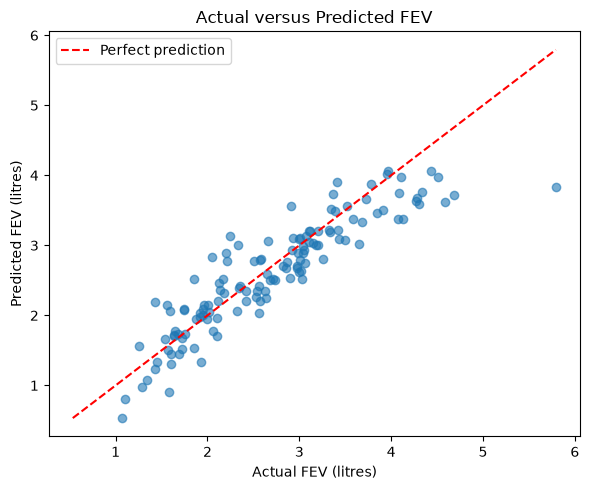

In [19]:
# Compare predicted FEV with actual test values
plt.figure(figsize=(6, 5))
plt.scatter(y_test, multiple_pred, alpha=0.6)

limits = [min(y_test.min(), multiple_pred.min()), max(y_test.max(), multiple_pred.max())]

plt.plot(limits, limits, "r--", label="Perfect prediction")
plt.xlabel("Actual FEV (litres)")
plt.ylabel("Predicted FEV (litres)")
plt.title("Actual versus Predicted FEV")
plt.legend()
plt.tight_layout()
plt.show()

The actual versus predicted FEV plot shows that most observations lie close to the perfect prediction line, indicating good predictive performance. However, the model tends to underestimate some higher FEV values and overestimate some lower values. This suggests that the model performs well overall but may be less accurate for extreme FEV values. The test R² of 0.806 supports the model's good predictive performance.

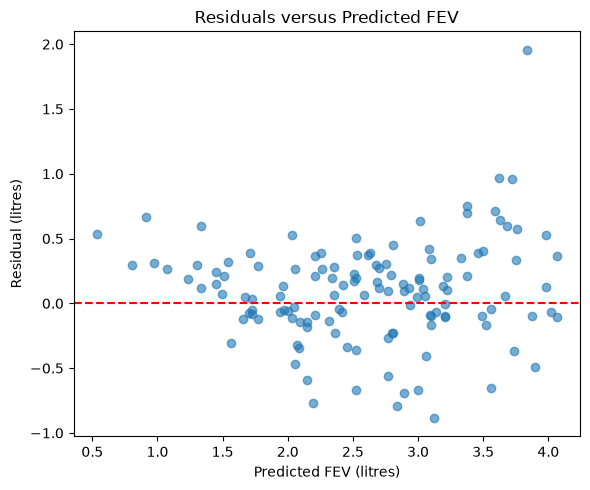

In [20]:
# Residual = actual value minus predicted value
residuals = y_test - multiple_pred

plt.figure(figsize=(6, 5))
plt.scatter(multiple_pred, residuals, alpha=0.6)
plt.axhline(0, color="red", linestyle="--")

plt.xlabel("Predicted FEV (litres)")
plt.ylabel("Residual (litres)")
plt.title("Residuals versus Predicted FEV")
plt.tight_layout()
plt.show()

The residual plot shows that most errors are scattered around zero, which suggests that the linear regression model is reasonable. However, the errors appear larger for higher predicted FEV values, and a few large errors are present. This means the model predicts FEV well overall, but its accuracy may vary across different FEV levels.

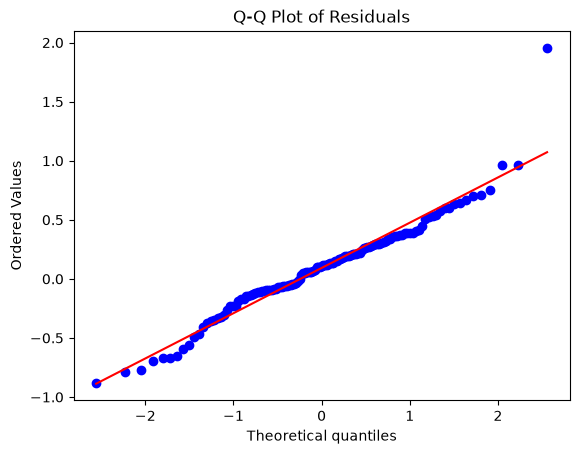

In [21]:
# Q-Q plot to check for normality
import scipy.stats as stats

stats.probplot(residuals, dist="norm", plot=plt)
plt.title("Q-Q Plot of Residuals")
plt.show()

The **Q-Q plot** shows that most residuals follow the reference line, suggesting that the residuals are approximately normally distributed. However, some deviations are visible at the tails, including one large outlier. Overall, the normality assumption appears reasonably satisfied, although it is not perfect.

## Conclusion

In this analysis, multiple linear regression was used to predict FEV (lung function) based on age, height, sex, and smoking status.
The multiple linear regression model performed much better than the mean baseline model. On the test dataset, it achieved an **R² of 0.806, MAE of 0.298, and RMSE of 0.399**. This indicates that the model explains approximately 80.6% of the variation in FEV and provides reasonably accurate predictions.

The 5-fold cross-validation results were also good, with an average R² of 0.755, suggesting that the model performs reasonably well.

The residual plot showed that most errors were scattered around zero, although the spread increased at higher predicted FEV values. The Q-Q plot indicated that the residuals were approximately normally distributed, with a few deviations and one noticeable outlier.

Overall, **multiple linear regression is a useful model for predicting FEV**. However, some prediction errors and possible unequal error variance suggest that the model could be improved further.